In [9]:
# CLEANING DATA

import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('employee_data.csv')
# getting rid of columns with unneccessary info
df_columns = df.drop(columns=['Title', 'Supervisor', 'ADEmail', 'BusinessUnit','EmployeeType', 'PayZone','EmployeeClassificationType','TerminationDescription','DepartmentType', 'Division', 'DOB', 'State', 'JobFunctionDescription', 'GenderCode', 'LocationCode', 'RaceDesc', 'MaritalDesc', 'Performance Score', 'Current Employee Rating'])
# removing null values from exit date
df_cleaned = df_columns.dropna()
#df_cleaned.head(3)

In [10]:
# DAYS AND YEARS WORKED

# convert the date into usable date
df_cleaned['StartDate'] = pd.to_datetime(df_cleaned['StartDate'])
df_cleaned['ExitDate'] = pd.to_datetime(df_cleaned['ExitDate'])

# subtract the dates to get the difference
df_cleaned['Days_Difference'] = df_cleaned['ExitDate'] - df_cleaned['StartDate']

# converts the result to a clean integer number of days
df_cleaned['Days_Int'] = df_cleaned['Days_Difference'].dt.days
# divided days to get total years
df_cleaned['Years'] = df_cleaned['Days_Int'] / 365
df_cleaned['Years'] = df_cleaned['Years'].round(2)
#df_cleaned.head(3)

/var/folders/hq/_qlkg5wj629b0ccpbrdm8w200000gn/T/ipykernel_11983/2975814483.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_cleaned['StartDate'] = pd.to_datetime(df_cleaned['StartDate'])
/var/folders/hq/_qlkg5wj629b0ccpbrdm8w200000gn/T/ipykernel_11983/2975814483.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_cleaned['ExitDate'] = pd.to_datetime(df_cleaned['ExitDate'])


In [11]:
# COUNT OF DIFFERENT TERMINATION TYPES

term_type_count = df_cleaned['TerminationType'].value_counts()
print("Count of " + str(term_type_count))

Count of TerminationType
Involuntary    388
Voluntary      388
Resignation    380
Retirement     377
Name: count, dtype: int64


In [12]:
# AVERAGE YEARS BEFORE TERMINATION

# average years spent with company if they left involuntarily
avg_years_invol = df_cleaned.loc[df['TerminationType'] == 'Involuntary', 'Years'].mean().round(2)
print("The average years with the company for people who left involuntarily is " + str(avg_years_invol))

# average years spent with company if they left voluntarily
avg_years_vol = df_cleaned.loc[df['TerminationType'] == 'Voluntary', 'Years'].mean().round(2)
print("The average years with the company for people who left voluntarily is " + str(avg_years_vol))

# average years spent with company if they resigned
avg_years_res = df_cleaned.loc[df['TerminationType'] == 'Resignation', 'Years'].mean().round(2)
print("The average years with the company for people who resigned is " + str(avg_years_res))

# average years spent with company if they retired
avg_years_ret = df_cleaned.loc[df['TerminationType'] == 'Retirement', 'Years'].mean().round(2)
print("The average years with the company for people who retired is " + str(avg_years_ret))


The average years with the company for people who left involuntarily is 1.41
The average years with the company for people who left voluntarily is 1.29
The average years with the company for people who resigned is 1.35
The average years with the company for people who retired is 1.3


In [13]:
# WHAT YEARS HAD THE MOST TERMINATIONS

df_cleaned['year_left'] = df_cleaned['ExitDate'].dt.year

year_invol = df_cleaned.loc[df['TerminationType'] == 'Involuntary', 'year_left'].value_counts().head(10)
print("Ranked years where people left involuntarily:")
print(year_invol)
print()

year_vol = df_cleaned.loc[df['TerminationType'] == 'Voluntary', 'year_left'].value_counts().head(10)
print("Ranked years where people left voluntarily:")
print(year_vol)
print()

year_res = df_cleaned.loc[df['TerminationType'] == 'Resignation', 'year_left'].value_counts().head(10)
print("Ranked years where people resigned:")
print(year_res)
print()

year_ret = df_cleaned.loc[df['TerminationType'] == 'Retirement', 'year_left'].value_counts().head(10)
print("Ranked years where people retired:")
print(year_ret)


Ranked years where people left involuntarily:
year_left
2023    170
2022     99
2021     71
2020     32
2019     15
2018      1
Name: count, dtype: int64

Ranked years where people left voluntarily:
year_left
2023    154
2022    116
2021     65
2020     38
2019     14
2018      1
Name: count, dtype: int64

Ranked years where people resigned:
year_left
2023    138
2022    118
2021     82
2020     28
2019     13
2018      1
Name: count, dtype: int64

Ranked years where people retired:
year_left
2023    134
2022    127
2021     60
2020     35
2019     20
2018      1
Name: count, dtype: int64


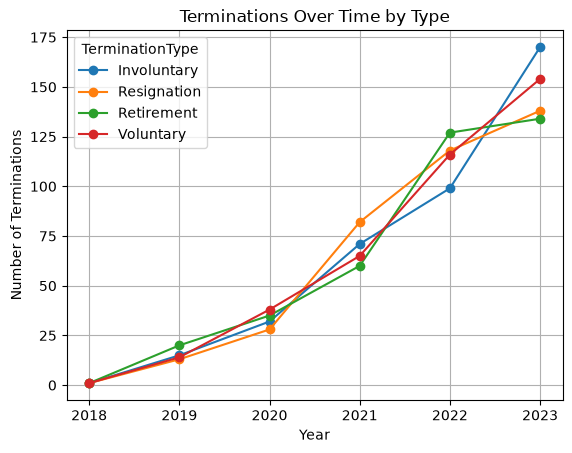

In [14]:
# LINE GRAPH OF TERMINATIONS PER YER BY TYPE

df_cleaned['year_left'] = df_cleaned['ExitDate'].dt.year

# group by both Year and Termination Type, then count occurrences
years_graph = df_cleaned.groupby(['year_left', 'TerminationType']).size().unstack(fill_value=0)

# plot the data
years_graph.plot(kind='line', marker='o')

plt.title('Terminations Over Time by Type')
plt.xlabel('Year')
plt.ylabel('Number of Terminations')
plt.grid(True)
plt.show()

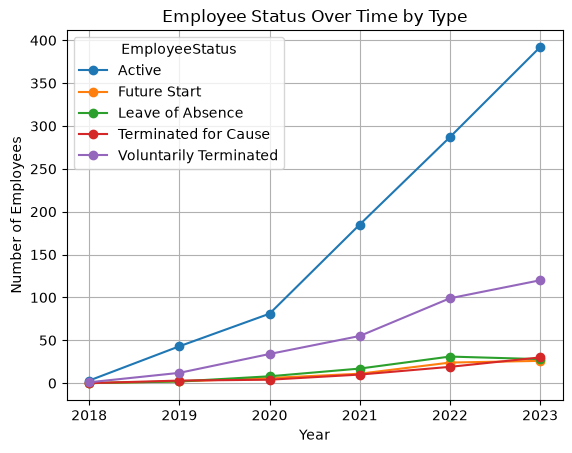

In [ ]:
# LINE GRAPH OF EMPLOYEE STATUS BY YEAR

df_cleaned['year_left'] = df_cleaned['ExitDate'].dt.year

# group by both Year and Termination Type, then count occurrences
years_graph = df_cleaned.groupby(['year_left', 'EmployeeStatus']).size().unstack(fill_value=0)

# plot the data
years_graph.plot(kind='line', marker='o')

plt.title('Employee Status Over Time by Type')
plt.xlabel('Year')
plt.ylabel('Number of Employees')
plt.grid(True)
plt.show()

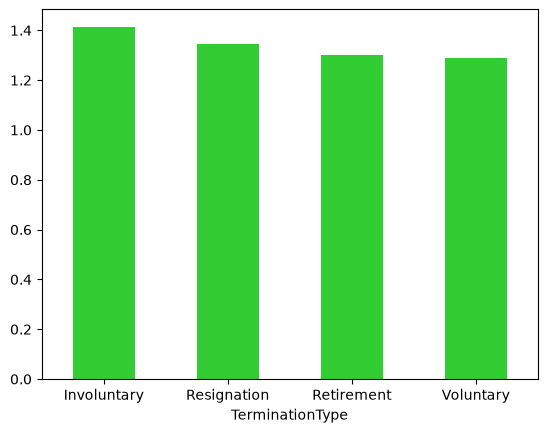

In [15]:
# BAR GRAPH OF AVERAGE YEARS AT COMPANY BY TYPE

df_cleaned['year_left'] = df_cleaned['ExitDate'].dt.year
df_cleaned.groupby('TerminationType')['Years'].mean().plot.bar(color='limegreen', rot=0)

plt.show()

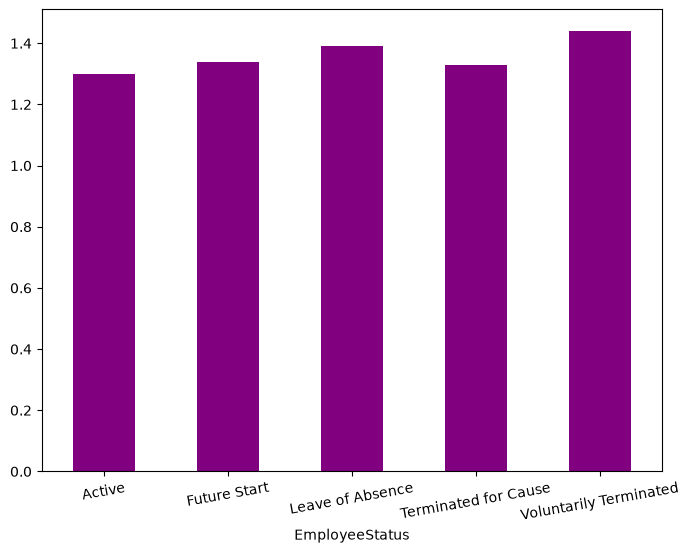

In [28]:
# BAR GRAPH OF AVERAGE YEARS AT COMPANY BY EMPLOYEE STATUS

import matplotlib.pyplot as plt

# 1. Create the year column from the exit date
df_cleaned['year_left'] = df_cleaned['ExitDate'].dt.year 

# 2. Group, calculate the mean, and plot correctly using .plot.bar()
df_cleaned.groupby('EmployeeStatus')['Years'].mean().plot.bar(
    color='purple', 
    rot=10, 
    figsize=(8, 6)
)

# 3. Render the chart
plt.show()

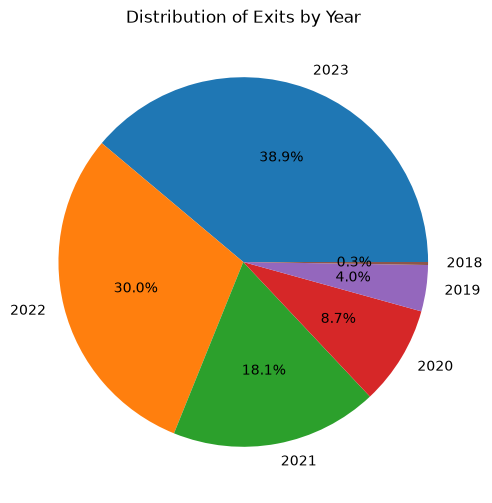

In [16]:
# PIE CHART OF EXIT YEAR

df_cleaned['year_left'].value_counts().plot(kind='pie', figsize=(6, 6), autopct='%1.1f%%')

plt.title("Distribution of Exits by Year")
plt.ylabel("") # Clears the column name text from the vertical axis
plt.show()
